In [ ]:
import os
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

# --- Chemins ---
BASE_DIR   = '/content/drive/MyDrive/projet_conso'
FINAL_PATH = f'{BASE_DIR}/data/processed/dataset_hourly.parquet'

# Vérification que le fichier existe bien
assert os.path.exists(FINAL_PATH), f'Fichier introuvable : {FINAL_PATH}'

df = pd.read_parquet(FINAL_PATH)
print(f'Dataset chargé : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')
print(f'Période : {df.index.min()} → {df.index.max()}')
df.head()

Mounted at /content/drive
Dataset chargé : 34,587 lignes × 15 colonnes
Période : 2006-12-16 18:00:00 → 2010-11-26 20:00:00


,global_active_power,global_reactive_power,voltage,global_intensity,sub_1_kitchen,sub_2_laundry,sub_3_heater_ac,unmetered_wh,hour,day_of_week,month,is_weekend,is_holiday,apparent_temperature,is_imputed
datetime,,,,,,,,,,,,,,,
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,2217.200000,18,5,12,1,0,3.7,0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,2313.233333,19,5,12,1,0,3.3,0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,2261.566667,20,5,12,1,0,3.2,0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1998.466667,21,5,12,1,0,3.2,0
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,8.0,266.0,1926.133333,22,5,12,1,0,2.6,0


In [ ]:
import matplotlib.pyplot as plt

def predict(model, loader):
    """Renvoie les prédictions du modèle."""
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(preds)

def to_kw(y):
    """Remet les valeurs en kW."""
    return y_scaler.inverse_transform(y.reshape(-1, 1)).reshape(y.shape)

def metrics(y_true, y_pred):
    """Calcule MAE, RMSE, MAPE et WAPE."""
    err = y_pred - y_true
    return {
        'MAE (kW)':  np.abs(err).mean(),
        'RMSE (kW)': np.sqrt((err ** 2).mean()),
        'MAPE (%)':  (np.abs(err) / y_true).mean() * 100,
        'WAPE (%)':  np.abs(err).sum() / y_true.sum() * 100,
    }

In [ ]:
import torch
from sklearn.preprocessing import StandardScaler

# --- Reproductibilité ---
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Paramètres du problème ---
TARGET   = 'global_active_power'
HORIZON  = 24  # on prédit les 24 prochaines heures
LOOKBACK = 48   # on regarde les 48 dernières heures (on testera 24 / 168 plus tard)

df = pd.read_parquet(FINAL_PATH)

# 1) Encodage cyclique : 23h et 0h deviennent proches
def add_cyclic(df):
    df = df.copy()
    for col, period in [('hour', 24), ('day_of_week', 7), ('month', 12)]:
        df[f'{col}_sin'] = np.sin(2 * np.pi * df[col] / period)
        df[f'{col}_cos'] = np.cos(2 * np.pi * df[col] / period)
    return df.drop(columns=['hour', 'day_of_week', 'month'])

df = add_cyclic(df)
FEATURES = [TARGET] + [c for c in df.columns if c not in (TARGET, 'is_imputed')]

# 2) Split temporel (jamais de mélange !)
train_df = df.loc[:'2008-12-31']
val_df   = df.loc['2009-01-01':'2009-12-31']
test_df  = df.loc['2010-01-01':]

# 3) Normalisation : apprise sur le TRAIN uniquement
x_scaler = StandardScaler().fit(train_df[FEATURES])
y_scaler = StandardScaler().fit(train_df[[TARGET]])   # pour dé-normaliser les prédictions

def scale(part):
    X = x_scaler.transform(part[FEATURES]).astype('float32')
    y = y_scaler.transform(part[[TARGET]]).ravel().astype('float32')
    return X, y, part['is_imputed'].values

# 4) Fenêtrage : X = L heures passées, y = 24 heures futures
def make_windows(X, y, imputed, lookback=LOOKBACK, horizon=HORIZON):
    Xs, ys, imp = [], [], []
    for t in range(lookback, len(X) - horizon + 1):
        Xs.append(X[t - lookback:t])
        ys.append(y[t:t + horizon])
        imp.append(imputed[t:t + horizon].any())   # cible contenant des heures imputées ?
    return np.array(Xs), np.array(ys), np.array(imp)

X_train, y_train, imp_train = make_windows(*scale(train_df))
X_val,   y_val,   imp_val   = make_windows(*scale(val_df))
X_test,  y_test,  imp_test  = make_windows(*scale(test_df))

print(f'Features ({len(FEATURES)}) : {FEATURES}')
print(f'Train : X {X_train.shape}  y {y_train.shape}')
print(f'Val   : X {X_val.shape}  y {y_val.shape}')
print(f'Test  : X {X_test.shape}  y {y_test.shape}  '
      f'(fenêtres avec cible imputée : {imp_test.sum()})')

# Version MLP : on aplatit (N, L, F) -> (N, L*F)
X_train_mlp = X_train.reshape(len(X_train), -1)
print(f'Entrée MLP : {X_train_mlp.shape}')

Features (17) : ['global_active_power', 'global_reactive_power', 'voltage', 'global_intensity', 'sub_1_kitchen', 'sub_2_laundry', 'sub_3_heater_ac', 'unmetered_wh', 'is_weekend', 'is_holiday', 'apparent_temperature', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']
Train : X (17839, 48, 17)  y (17839, 24)
Val   : X (8689, 48, 17)  y (8689, 24)
Test  : X (7846, 48, 17)  y (7846, 24)  (fenêtres avec cible imputée : 386)
Entrée MLP : (17839, 816)


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device :', device)

# Aplatir : (N, 48, F) -> (N, 48*F)
def flatten(X):
    return X.reshape(len(X), -1)

Xtr, Xva, Xte = flatten(X_train), flatten(X_val), flatten(X_test)

# NumPy -> tenseurs PyTorch
train_ds = TensorDataset(torch.tensor(Xtr), torch.tensor(y_train))
val_ds   = TensorDataset(torch.tensor(Xva), torch.tensor(y_val))
test_ds  = TensorDataset(torch.tensor(Xte), torch.tensor(y_test))

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)   # mélange OK : les fenêtres sont déjà construites
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

n_inputs = Xtr.shape[1]
print(f'Entrée MLP : {n_inputs} valeurs  |  Sortie : {HORIZON} valeurs')

Device : cuda
Entrée MLP : 816 valeurs  |  Sortie : 24 valeurs


In [ ]:
class MLP(nn.Module):
    """MLP : 48h d'historique aplaties -> 24h de consommation prédites."""
    def __init__(self, n_inputs, horizon=24, hidden=(256, 128), dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_inputs, hidden[0]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[1], horizon),
        )

    def forward(self, x):
        return self.net(x)


In [ ]:
def train_model(model, train_loader, val_loader, lr=1e-3, optimizer_name='adam',
                n_epochs=100, patience=10,weight_decay=0.0):
    """Boucle de descente de gradient avec early stopping sur la loss de validation."""
    loss_fn = nn.MSELoss()
    if optimizer_name == 'sgd':
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr,weight_decay=weight_decay)

    history = {'train': [], 'val': []}
    best_val, best_state, wait = float('inf'), None, 0

    for epoch in range(n_epochs):
        # ---- Entraînement ----
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()          # 1. remettre les gradients à 0
            y_pred = model(xb)             # 2. forward : prédiction
            loss = loss_fn(y_pred, yb)     # 3. calcul de l'erreur
            loss.backward()                # 4. rétropropagation : gradients ∂L/∂θ
            optimizer.step()               # 5. mise à jour : θ ← θ − lr·∇L
            train_loss += loss.item() * len(xb)
        train_loss /= len(train_loader.dataset)

        # ---- Validation (pas de gradient) ----
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_loss += loss_fn(model(xb), yb).item() * len(xb)
        val_loss /= len(val_loader.dataset)

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f'Epoch {epoch+1:3d} | train {train_loss:.4f} | val {val_loss:.4f}')

        # ---- Early stopping ----
        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f'Arrêt anticipé à l\'epoch {epoch+1}')
                break

    model.load_state_dict(best_state)   # on garde le meilleur modèle
    return model, history




In [ ]:
# Configuration de référence : chaque étude ne change qu'UN paramètre
REF = dict(hidden=(128, 64), dropout=0.3, lr=1e-4, optimizer='adam',
           batch_size=64, weight_decay=1e-4)

def run_experiment(label, **changes):
    """Entraîne un MLP avec la config de référence + les changements donnés."""
    cfg = {**REF, **changes}
    torch.manual_seed(SEED)
    loader = DataLoader(train_ds, batch_size=cfg['batch_size'], shuffle=True)
    m = MLP(n_inputs, hidden=cfg['hidden'], dropout=cfg['dropout']).to(device)
    print(f'\n=== {label} ===')
    _, h = train_model(m, loader, val_loader, lr=cfg['lr'],
                       optimizer_name=cfg['optimizer'],
                       weight_decay=cfg['weight_decay'], patience=15, n_epochs=60)
    return label, h

def plot_experiments(results, title):
    """Superpose les courbes de validation de plusieurs essais."""
    plt.figure(figsize=(9, 4))
    for label, h in results:
        plt.plot(h['val'], label=f"{label} (min {min(h['val']):.3f})")
    plt.xlabel('Epoch'); plt.ylabel('MSE validation'); plt.legend()
    plt.title(title); plt.show()


=== hidden = (256, 128) ===
Epoch   1 | train 0.7894 | val 0.4765
Epoch   2 | train 0.6658 | val 0.4585
Epoch   3 | train 0.6336 | val 0.4482
Epoch   4 | train 0.6142 | val 0.4451
Epoch   5 | train 0.5980 | val 0.4411
Epoch   6 | train 0.5887 | val 0.4392
Epoch   7 | train 0.5764 | val 0.4372
Epoch   8 | train 0.5724 | val 0.4388
Epoch   9 | train 0.5653 | val 0.4396
Epoch  10 | train 0.5588 | val 0.4380
Epoch  11 | train 0.5511 | val 0.4419
Epoch  12 | train 0.5459 | val 0.4400
Epoch  13 | train 0.5424 | val 0.4392
Epoch  14 | train 0.5365 | val 0.4381
Epoch  15 | train 0.5337 | val 0.4349
Epoch  16 | train 0.5279 | val 0.4386
Epoch  17 | train 0.5262 | val 0.4388
Epoch  18 | train 0.5216 | val 0.4371
Epoch  19 | train 0.5195 | val 0.4383
Epoch  20 | train 0.5159 | val 0.4385
Epoch  21 | train 0.5135 | val 0.4409
Epoch  22 | train 0.5104 | val 0.4357
Epoch  23 | train 0.5075 | val 0.4401
Epoch  24 | train 0.5052 | val 0.4374
Epoch  25 | train 0.5013 | val 0.4361
Epoch  26 | train 0.4

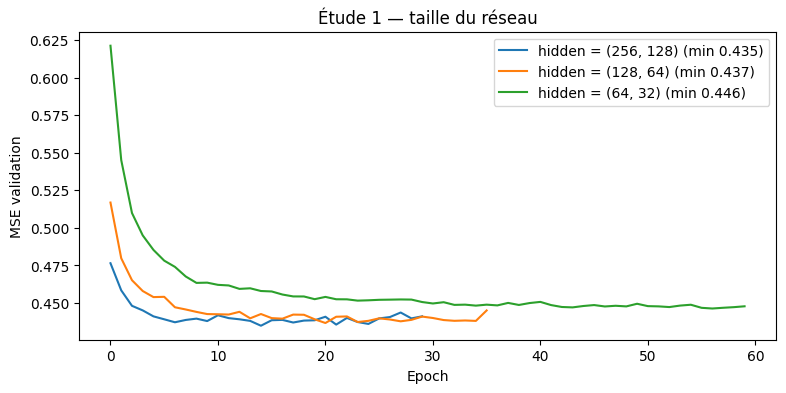

In [ ]:
exp_hidden = [run_experiment(f'hidden = {h}', hidden=h)
              for h in [(256, 128), (128, 64), (64, 32)]]
plot_experiments(exp_hidden, 'Étude 1 — taille du réseau')

Le petit réseau (64 → 32) est trop limité. Il apprend lentement (60 epochs) et finit plus haut : c’est du sous-apprentissage.
Les deux plus grands réseaux sont quasiment à égalité. L’écart de 0,002 est très faible.
Choix retenu : 256 → 128, car il a la meilleure loss de validation. Note ce résultat, on l’utilisera à la fin dans

Un réseau trop petit sous-apprend. Au-delà de 128 → 64, agrandir le réseau n’apporte presque plus rien.


=== dropout = 0.0 ===
Epoch   1 | train 0.7615 | val 0.4809
Epoch   2 | train 0.6096 | val 0.4602
Epoch   3 | train 0.5792 | val 0.4481
Epoch   4 | train 0.5603 | val 0.4452
Epoch   5 | train 0.5468 | val 0.4456
Epoch   6 | train 0.5362 | val 0.4469
Epoch   7 | train 0.5274 | val 0.4412
Epoch   8 | train 0.5198 | val 0.4442
Epoch   9 | train 0.5129 | val 0.4450
Epoch  10 | train 0.5070 | val 0.4432
Epoch  11 | train 0.5014 | val 0.4500
Epoch  12 | train 0.4959 | val 0.4486
Epoch  13 | train 0.4906 | val 0.4534
Epoch  14 | train 0.4855 | val 0.4528
Epoch  15 | train 0.4808 | val 0.4551
Epoch  16 | train 0.4765 | val 0.4550
Epoch  17 | train 0.4722 | val 0.4553
Epoch  18 | train 0.4682 | val 0.4608
Epoch  19 | train 0.4639 | val 0.4617
Epoch  20 | train 0.4604 | val 0.4613
Epoch  21 | train 0.4563 | val 0.4591
Epoch  22 | train 0.4528 | val 0.4616
Arrêt anticipé à l'epoch 22

=== dropout = 0.2 ===
Epoch   1 | train 0.8226 | val 0.4970
Epoch   2 | train 0.6850 | val 0.4684
Epoch   3 | tr

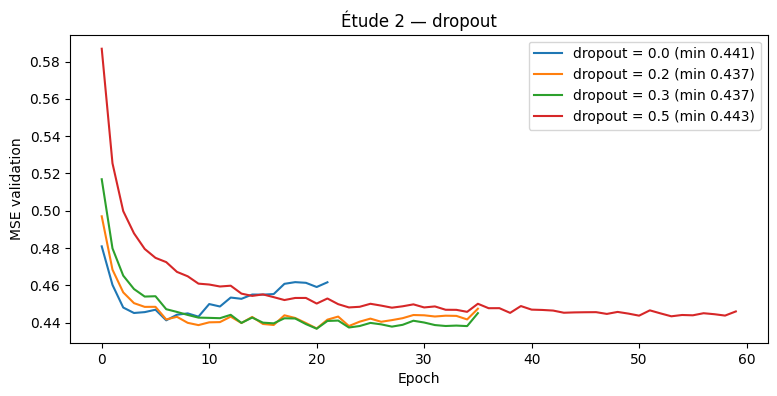

In [ ]:
exp_dropout = [run_experiment(f'dropout = {d}', dropout=d)
               for d in [0.0, 0.2, 0.3, 0.5]]
plot_experiments(exp_dropout, 'Étude 2 — dropout')

Sans dropout, le modèle apprend par cœur dès l’epoch 7. Un dropout modéré (0,2-0,3) retarde le sur-apprentissage, alors qu’un dropout trop fort (0,5) l’empêche d’apprendre assez.

Sans dropout (0,0), le modèle sur-apprend vite. Son meilleur score arrive dès l’epoch 7. Ensuite la loss de train continue de baisser (jusqu’à 0,45) pendant que la validation remonte (jusqu’à 0,46).
Avec 0,2 et 0,3, le modèle apprend plus longtemps (minimum à l’epoch 21) et obtient un meilleur score. Les deux sont à égalité.
0,5 est trop fort. Le modèle est freiné et reste nettement plus haut, à 0,452 ou plus à l’epoch 20.
Choix retenu : 0,3, la meilleure valeur, même si l’écart avec 0,2 est minime.


=== weight decay = 0.0 ===
Epoch   1 | train 0.8540 | val 0.5168
Epoch   2 | train 0.7220 | val 0.4796
Epoch   3 | train 0.6859 | val 0.4650
Epoch   4 | train 0.6627 | val 0.4579
Epoch   5 | train 0.6469 | val 0.4540
Epoch   6 | train 0.6344 | val 0.4541
Epoch   7 | train 0.6253 | val 0.4472
Epoch   8 | train 0.6137 | val 0.4456
Epoch   9 | train 0.6090 | val 0.4442
Epoch  10 | train 0.6044 | val 0.4426
Epoch  11 | train 0.6006 | val 0.4424
Epoch  12 | train 0.5965 | val 0.4422
Epoch  13 | train 0.5912 | val 0.4436
Epoch  14 | train 0.5859 | val 0.4399
Epoch  15 | train 0.5838 | val 0.4428
Epoch  16 | train 0.5814 | val 0.4399
Epoch  17 | train 0.5784 | val 0.4395
Epoch  18 | train 0.5741 | val 0.4422
Epoch  19 | train 0.5735 | val 0.4421
Epoch  20 | train 0.5697 | val 0.4391
Epoch  21 | train 0.5696 | val 0.4368
Epoch  22 | train 0.5643 | val 0.4406
Epoch  23 | train 0.5642 | val 0.4407
Epoch  24 | train 0.5631 | val 0.4372
Epoch  25 | train 0.5613 | val 0.4380
Epoch  26 | train 0.55

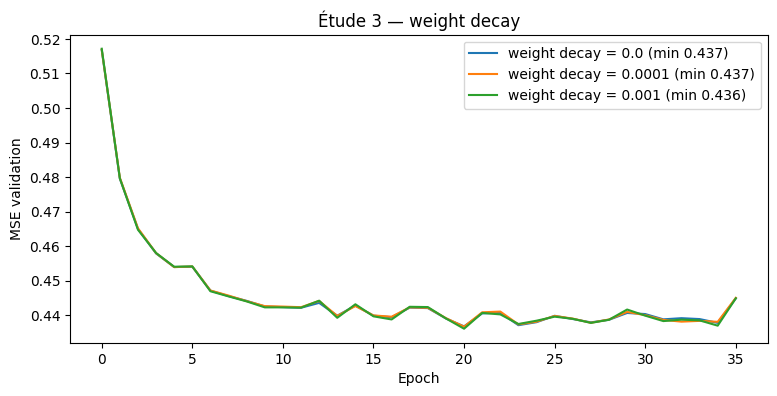

In [ ]:
exp_wd = [run_experiment(f'weight decay = {w}', weight_decay=w)
          for w in [0.0, 1e-4, 1e-3]]
plot_experiments(exp_wd, 'Étude 3 — weight decay')

les trois courbes sont presque superposées. Dans cette plage de valeurs, le weight decay n’a quasiment aucun effet. L’écart de 0,001 relève du hasard, pas d’une vraie différence.


=== SGD + momentum ===
Epoch   1 | train 0.9735 | val 0.6971
Epoch   2 | train 0.8894 | val 0.6263
Epoch   3 | train 0.8231 | val 0.5669
Epoch   4 | train 0.7726 | val 0.5233
Epoch   5 | train 0.7388 | val 0.5003
Epoch   6 | train 0.7205 | val 0.4899
Epoch   7 | train 0.7073 | val 0.4834
Epoch   8 | train 0.6949 | val 0.4786
Epoch   9 | train 0.6865 | val 0.4749
Epoch  10 | train 0.6817 | val 0.4716
Epoch  11 | train 0.6762 | val 0.4691
Epoch  12 | train 0.6711 | val 0.4669
Epoch  13 | train 0.6657 | val 0.4653
Epoch  14 | train 0.6591 | val 0.4632
Epoch  15 | train 0.6564 | val 0.4624
Epoch  16 | train 0.6525 | val 0.4595
Epoch  17 | train 0.6491 | val 0.4586
Epoch  18 | train 0.6438 | val 0.4571
Epoch  19 | train 0.6418 | val 0.4562
Epoch  20 | train 0.6379 | val 0.4555
Epoch  21 | train 0.6372 | val 0.4535
Epoch  22 | train 0.6324 | val 0.4525
Epoch  23 | train 0.6323 | val 0.4524
Epoch  24 | train 0.6283 | val 0.4509
Epoch  25 | train 0.6256 | val 0.4497
Epoch  26 | train 0.6256 |

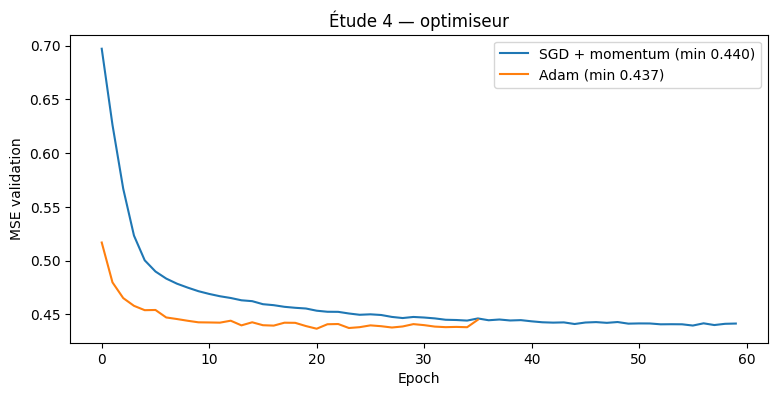

In [ ]:
# Étude 4 — Optimiseur
exp_optim = [run_experiment('SGD + momentum', optimizer='sgd', lr=1e-3),
             run_experiment('Adam', optimizer='adam')]
plot_experiments(exp_optim, 'Étude 4 — optimiseur')

Adam converge beaucoup plus vite. SGD démarre très haut (0,70) et met environ 50 epochs à rejoindre le niveau qu’Adam atteint en une dizaine.
Les deux arrivent presque au même niveau : ce qui change, c’est la vitesse, pas le résultat final.
Choix retenu : Adam


=== lr = 0.01 ===
Epoch   1 | train 0.8325 | val 0.5667
Epoch   2 | train 0.8271 | val 0.6112
Epoch   3 | train 0.8337 | val 0.5793
Epoch   4 | train 0.8282 | val 0.5931
Epoch   5 | train 0.8301 | val 0.5714
Epoch   6 | train 0.8478 | val 0.6407
Epoch   7 | train 0.8421 | val 0.5953
Epoch   8 | train 0.8269 | val 0.5765
Epoch   9 | train 0.8293 | val 0.6104
Epoch  10 | train 0.8393 | val 0.5835
Epoch  11 | train 0.8351 | val 0.5596
Epoch  12 | train 0.8270 | val 0.5960
Epoch  13 | train 0.8358 | val 0.5751
Epoch  14 | train 0.8339 | val 0.5766
Epoch  15 | train 0.8301 | val 0.6088
Epoch  16 | train 0.8351 | val 0.5837
Epoch  17 | train 0.8331 | val 0.5790
Epoch  18 | train 0.8818 | val 0.6362
Epoch  19 | train 0.8435 | val 0.5822
Epoch  20 | train 0.8442 | val 0.5808
Epoch  21 | train 0.8286 | val 0.5970
Epoch  22 | train 0.8309 | val 0.6090
Epoch  23 | train 0.8347 | val 0.5974
Epoch  24 | train 0.8286 | val 0.5912
Epoch  25 | train 0.8236 | val 0.5812
Epoch  26 | train 0.8381 | val 

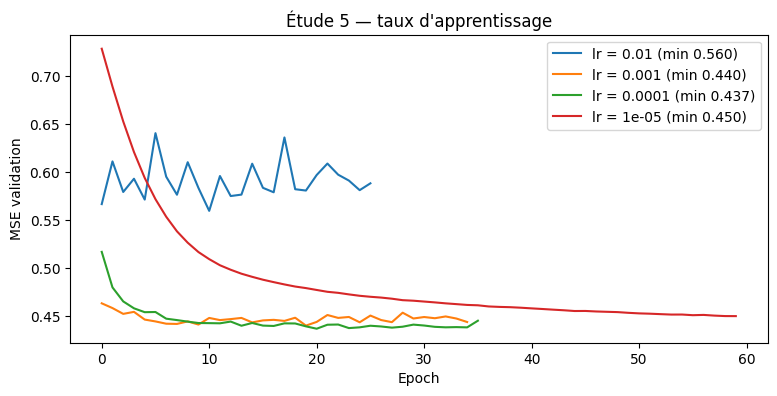

In [ ]:
# Étude 5 — Learning rate
exp_lr = [run_experiment(f'lr = {lr}', lr=lr) for lr in [1e-2, 1e-3, 1e-4, 1e-5]]
plot_experiments(exp_lr, "Étude 5 — taux d'apprentissage")

C’est l’hyperparamètre le plus sensible de toute ton étude : il fait varier la loss de 0,437 à 0,560.
choix : : 1e-4, le bon compromis.

taille du batch, c’est le nombre d’exemples que le modèle regarde avant de corriger ses poids.


=== batch = 8 ===
Epoch   1 | train 0.7545 | val 0.4704
Epoch   2 | train 0.6598 | val 0.4578
Epoch   3 | train 0.6303 | val 0.4452
Epoch   4 | train 0.6137 | val 0.4448
Epoch   5 | train 0.6041 | val 0.4445
Epoch   6 | train 0.5920 | val 0.4414
Epoch   7 | train 0.5861 | val 0.4407
Epoch   8 | train 0.5798 | val 0.4414
Epoch   9 | train 0.5764 | val 0.4401
Epoch  10 | train 0.5690 | val 0.4345
Epoch  11 | train 0.5664 | val 0.4416
Epoch  12 | train 0.5629 | val 0.4389
Epoch  13 | train 0.5598 | val 0.4417
Epoch  14 | train 0.5571 | val 0.4382
Epoch  15 | train 0.5525 | val 0.4413
Epoch  16 | train 0.5527 | val 0.4437
Epoch  17 | train 0.5470 | val 0.4382
Epoch  18 | train 0.5462 | val 0.4394
Epoch  19 | train 0.5412 | val 0.4435
Epoch  20 | train 0.5425 | val 0.4416
Epoch  21 | train 0.5400 | val 0.4381
Epoch  22 | train 0.5356 | val 0.4408
Epoch  23 | train 0.5355 | val 0.4398
Epoch  24 | train 0.5331 | val 0.4414
Epoch  25 | train 0.5311 | val 0.4405
Arrêt anticipé à l'epoch 25

==

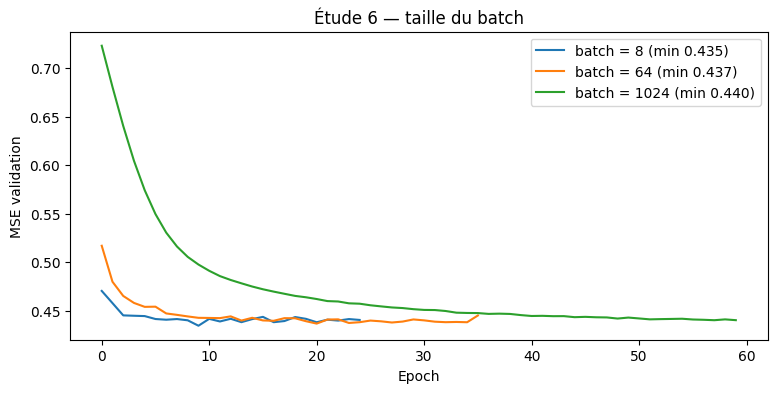

In [ ]:
# Étude 6 — Taille du batch des exemple
exp_batch = [run_experiment(f'batch = {bs}', batch_size=bs) for bs in [8, 64, 1024]]
plot_experiments(exp_batch, 'Étude 6 — taille du batch')

Le batch 1024 converge lentement, faute de mises à jour. Les batchs 8 et 64 donnent le même résultat, et j’ai retenu 64, beaucoup plus rapide

Epoch   1 | train 0.7892 | val 0.4766
Epoch   2 | train 0.6649 | val 0.4585
Epoch   3 | train 0.6328 | val 0.4483
Epoch   4 | train 0.6133 | val 0.4452
Epoch   5 | train 0.5971 | val 0.4410
Epoch   6 | train 0.5881 | val 0.4389
Epoch   7 | train 0.5759 | val 0.4369
Epoch   8 | train 0.5722 | val 0.4388
Epoch   9 | train 0.5653 | val 0.4400
Epoch  10 | train 0.5590 | val 0.4385
Epoch  11 | train 0.5515 | val 0.4420
Epoch  12 | train 0.5469 | val 0.4408
Epoch  13 | train 0.5438 | val 0.4400
Epoch  14 | train 0.5381 | val 0.4380
Epoch  15 | train 0.5351 | val 0.4353
Epoch  16 | train 0.5303 | val 0.4406
Epoch  17 | train 0.5285 | val 0.4394
Epoch  18 | train 0.5246 | val 0.4372
Epoch  19 | train 0.5231 | val 0.4375
Epoch  20 | train 0.5192 | val 0.4385
Epoch  21 | train 0.5169 | val 0.4417
Epoch  22 | train 0.5144 | val 0.4358
Epoch  23 | train 0.5122 | val 0.4405
Epoch  24 | train 0.5103 | val 0.4376
Epoch  25 | train 0.5062 | val 0.4360
Epoch  26 | train 0.5049 | val 0.4412
Epoch  27 | 

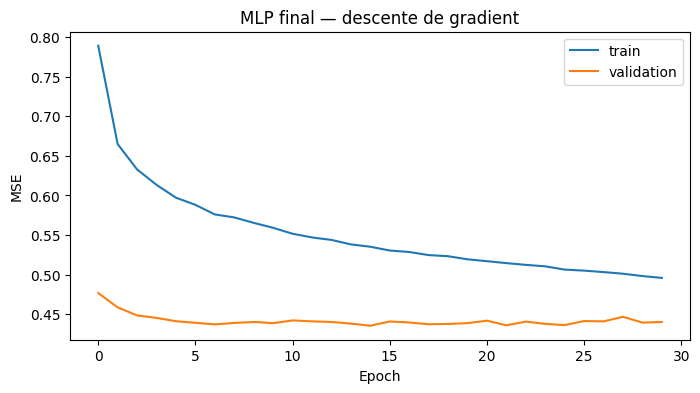

Meilleure loss val : 0.4353


In [ ]:
# Modèle final : meilleurs hyperparamètres trouvés par l'étude
BEST = dict(hidden=(256, 128), dropout=0.3, lr=1e-4, optimizer='adam',
            batch_size=64, weight_decay=1e-3)

torch.manual_seed(SEED)
final_loader = DataLoader(train_ds, batch_size=BEST['batch_size'], shuffle=True)
mlp_final = MLP(n_inputs, hidden=BEST['hidden'], dropout=BEST['dropout']).to(device)
mlp_final, hist_final = train_model(mlp_final, final_loader, val_loader,
                                    lr=BEST['lr'], optimizer_name=BEST['optimizer'],
                                    weight_decay=BEST['weight_decay'], patience=15)

plt.figure(figsize=(8, 4))
plt.plot(hist_final['train'], label='train')
plt.plot(hist_final['val'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()
plt.title('MLP final — descente de gradient'); plt.show()
print(f"Meilleure loss val : {min(hist_final['val']):.4f}")

In [ ]:
# Évaluation UNIQUE sur le test (2010)
y_pred_kw    = to_kw(predict(mlp_final, test_loader))
y_true_kw    = to_kw(y_test)
y_persist_kw = to_kw(X_test[:, -24:, 0])   # persistance J-1 : la veille
keep = ~imp_test                           # on exclut les cibles imputées

results = pd.DataFrame({
    'Persistance J-1': metrics(y_true_kw[keep], y_persist_kw[keep]),
    'MLP final':       metrics(y_true_kw[keep], y_pred_kw[keep]),
}).T.round(3)
display(results)

,MAE (kW),RMSE (kW),MAPE (%),WAPE (%)
Persistance J-1,0.555,0.820,67.961998,52.334000
MLP final,0.469,0.623,65.646004,44.233002


Le gain le plus fort concerne la RMSE (−24 %), la métrique qui pénalise les grosses erreurs. Le MLP évite les gros ratés de la persistance (par exemple recopier une lessive de la veille), car il apprend un profil de consommation au lieu de recopier hier.
Le résultat est quasi identique à ton ancien MLP (0,470 / 0,620). C’est cohérent avec ton étude : toutes les bonnes configurations arrivent au même plancher, fixé par le bruit des données. Maintenant, chaque réglage est justifié par une étude.
La MAPE reste gonflée par les heures de nuit à faible consommation. Utilise la WAPE comme métrique en %.

Le gain le plus fort concerne la RMSE : le MLP évite les grosses erreurs de la persistance.

La MAPE (67 %) est gonflée par les heures de nuit à faible consommation.
Exemple : 0,2 kW d’erreur sur 0,2 kW réel donne déjà 100 %.
La WAPE rapporte l’erreur totale à la consommation totale, ce qui la rend plus fiable.


=== historique 24 h (408 entrées) ===
Epoch   1 | train 0.8939 | val 0.5643
Epoch   2 | train 0.7494 | val 0.4998
Epoch   3 | train 0.7041 | val 0.4843
Epoch   4 | train 0.6830 | val 0.4754
Epoch   5 | train 0.6662 | val 0.4682
Epoch   6 | train 0.6563 | val 0.4655
Epoch   7 | train 0.6477 | val 0.4625
Epoch   8 | train 0.6384 | val 0.4606
Epoch   9 | train 0.6334 | val 0.4587
Epoch  10 | train 0.6300 | val 0.4586
Epoch  11 | train 0.6246 | val 0.4552
Epoch  12 | train 0.6194 | val 0.4559
Epoch  13 | train 0.6183 | val 0.4556
Epoch  14 | train 0.6140 | val 0.4536
Epoch  15 | train 0.6109 | val 0.4524
Epoch  16 | train 0.6084 | val 0.4541
Epoch  17 | train 0.6059 | val 0.4523
Epoch  18 | train 0.6028 | val 0.4511
Epoch  19 | train 0.6004 | val 0.4502
Epoch  20 | train 0.5995 | val 0.4489
Epoch  21 | train 0.5977 | val 0.4522
Epoch  22 | train 0.5955 | val 0.4528
Epoch  23 | train 0.5948 | val 0.4508
Epoch  24 | train 0.5935 | val 0.4501
Epoch  25 | train 0.5919 | val 0.4504
Epoch  26 |

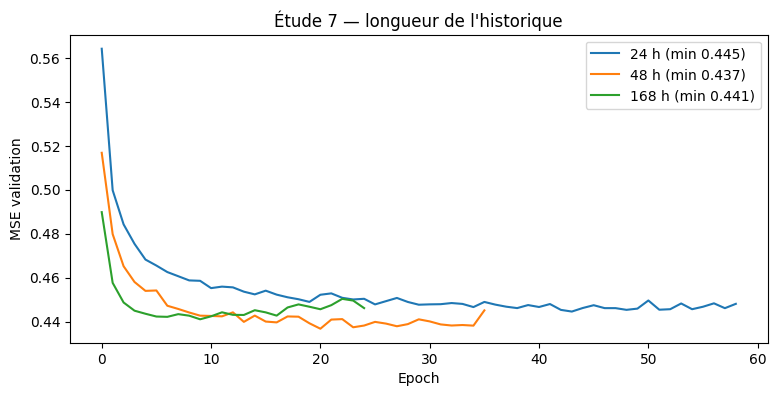

In [ ]:
# Étude 7 — Longueur de l'historique
def build_mlp_data(lookback):
    """Refait les fenêtres avec une autre longueur d'historique, puis aplatit pour le MLP."""
    Xtr, ytr, _ = make_windows(*scale(train_df), lookback=lookback)
    Xva, yva, _ = make_windows(*scale(val_df),   lookback=lookback)
    tr = DataLoader(TensorDataset(torch.tensor(flatten(Xtr)), torch.tensor(ytr)),
                    batch_size=64, shuffle=True)
    va = DataLoader(TensorDataset(torch.tensor(flatten(Xva)), torch.tensor(yva)),
                    batch_size=64)
    return tr, va

exp_lookback_mlp = []
for L in [24, 48, 168]:
    tr_l, va_l = build_mlp_data(L)
    torch.manual_seed(SEED)
    m = MLP(L * len(FEATURES), hidden=REF['hidden'], dropout=REF['dropout']).to(device)
    print(f'\n=== historique {L} h ({L * len(FEATURES)} entrées) ===')
    _, h = train_model(m, tr_l, va_l, lr=REF['lr'], optimizer_name=REF['optimizer'],
                       weight_decay=REF['weight_decay'], patience=15, n_epochs=60)
    exp_lookback_mlp.append((f'{L} h', h))

plot_experiments(exp_lookback_mlp, "Étude 7 — longueur de l'historique")

In [ ]:
# Calcul : évolution de l'erreur du MLP selon la longueur de l'historique
h1, h2 = REF['hidden']
rows = []
for (label, h), L in zip(exp_lookback_mlp, [24, 48, 168]):
    n_in = L * len(FEATURES)
    n_params = n_in * h1 + h1 + h1 * h2 + h2 + h2 * HORIZON + HORIZON
    rows.append({'Historique': label,
                 'Entrées': n_in,
                 'Paramètres': n_params,
                 'MSE val (min)': round(min(h['val']), 4),
                 'Epoch du minimum': int(np.argmin(h['val'])) + 1})

table_L = pd.DataFrame(rows)
ref = table_L.loc[table_L['Historique'] == '48 h', 'MSE val (min)'].item()
table_L['Écart vs 48 h (%)'] = ((table_L['MSE val (min)'] - ref) / ref * 100).round(1)
display(table_L)

,Historique,Entrées,Paramètres,MSE val (min),Epoch du minimum,Écart vs 48 h (%)
0,24 h,408,62168,0.4445,44,1.8
1,48 h,816,114392,0.4367,21,0.0
2,168 h,2856,375512,0.4410,10,1.0


0,4367 est plus petit que 0,4410. Donc 48 h est meilleur pour le MLP. Avec 168 h, la MSE augmente.

**MLP : plus d’historique, c’est moins bien (0,4367 → 0,4410)**.

Avec 168 h, le modèle dispose d’une information que les deux autres n’ont pas. C’est cohérent avec le résultat : plus il voit loin, mieux il prédit.